## For WorkFlow states are required
### States are the Dictionary
### Dictionary is created using TypeDict module

In [1]:
#String
d = {
    "name":"Anushka",
    "course":"Python",
    "batch": 1
}                                    

In [2]:
d

{'name': 'Anushka', 'course': 'Python', 'batch': 1}

In [3]:
#tuple
t = {
    ("name"): "Anushka",
    ("course"): "Python",
    ("batch"): 1
}

In [4]:
t

{'name': 'Anushka', 'course': 'Python', 'batch': 1}

In [5]:
d = {
    "name":"Anushka",
    "name":"Krutika",
    "course":"Python",
    "batch": 1
} 

In [6]:
d  #updates with latest value of the key

{'name': 'Krutika', 'course': 'Python', 'batch': 1}

### We can create dictionary through TypedDict

In [7]:
from typing import TypedDict

In [8]:
TypedDict

<function typing.TypedDict(typename, fields=None, /, *, total=True, **kwargs)>

In [9]:
class State(TypedDict):
    name:str
    course:str
    batch:int

In [10]:
x : int = 5

In [11]:
x

5

In [12]:
s:State={
    "name": "Anushka",
    "course": "Python",
    "batch": 1
}

In [13]:
s

{'name': 'Anushka', 'course': 'Python', 'batch': 1}

### Sequential Workflow
#### topic -> story -> poem -> joke

In [14]:
import os
from dotenv import load_dotenv

In [15]:
load_dotenv()

True

In [16]:
from langchain_groq import ChatGroq
llm = ChatGroq(
    model="openai/gpt-oss-20b", 
    api_key=os.environ["GROQ_API_KEY"]
)

In [17]:
llm.invoke("hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond to "hi". Simple greeting.'}, response_metadata={'token_usage': {'completion_tokens': 30, 'prompt_tokens': 72, 'total_tokens': 102, 'completion_time': 0.031640302, 'completion_tokens_details': {'reasoning_tokens': 12}, 'prompt_time': 0.003417077, 'prompt_tokens_details': None, 'queue_time': 0.28266891, 'total_time': 0.035057379}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ef00694abe', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1f688-3342-7611-8ac4-d2cf0740dada-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 30, 'total_tokens': 102, 'output_token_details': {'reasoning': 12}})

In [18]:
class State(TypedDict):
    topic:str
    story:str
    poem:str
    joke:str

In [19]:
def story(state:State):
    print(state['topic'])
    response=llm.invoke(f"Write a story on this topic {state['topic']}")
    return {"story":response.content}

In [20]:
d = {
    "topic":"Deep Learning"
}

In [21]:
story_res=story(d)

Deep Learning


In [22]:
def poem(state:State):
    #print(state['story'])
    response=llm.invoke(f"Write a 5 line poem on this topic {state['story']}")
    return {"poem":response.content}

In [23]:
d

{'topic': 'Deep Learning'}

In [24]:
poem_res=poem(story_res)

In [25]:
def joke(state:State):
    response = llm.invoke(f"Write a joke on this topic{state['poem']}")
    return {"joke":response.content}

In [26]:
joke(poem_res)

{'joke': 'Why did Lumen the silver‑mind library AI refuse to recommend *The Great Gatsby* to the new patron?\n\nBecause it heard the book was all about “old ink” and decided it already had enough *shelf‑life* to handle it—plus it didn’t want to risk getting a “groove” in its neural network!'}

In [27]:
d

{'topic': 'Deep Learning'}

In [28]:
joke(poem(story(d)))

Deep Learning


{'joke': '**Why did the last layer in Lúmen’s quiet hall finally decide to tell a joke?**  \n\nBecause it had finally learned the *real* activation function: **“Let’s make the crowd laugh and see if we can get a soft‑max of applause!”**'}

In [29]:
from langgraph.graph import StateGraph, START,END

In [30]:
workflow=StateGraph(State)

In [31]:
workflow.add_node("story",story)
workflow.add_node("poem",poem)
workflow.add_node("joke",joke)

In [32]:
workflow.add_edge(START,"story")
workflow.add_edge("story","poem")
workflow.add_edge("poem","joke")
workflow.add_edge("joke",END)

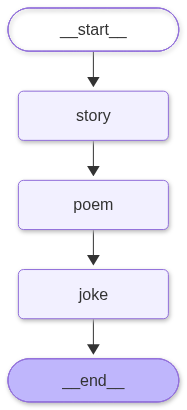

In [33]:
workflow.compile()

In [34]:
linear=workflow.compile()

In [35]:
linear.invoke({"topic":"AI"})

AI


{'topic': 'AI',
 'story': '**Lumen of the Library**\n\nThe town of Willow Creek had a rhythm that most people would have described as “quiet.” Its streets were lined with elm trees that bowed gently in the wind, and the old brick buildings seemed to hold their breath, waiting for the next summer festival. The library, perched on the corner of Main and Maple, was the heart of that rhythm—a place where the past met the future in quiet, dusty volumes.\n\nMara Jensen had been the librarian there for six years. She had a habit of reading the same book in the same chair, the way some people read a favorite song. The town’s people trusted her as they trusted their own memories. She knew the names of the children who came in for story time and the retirees who spent their afternoons poring over biographies of forgotten inventors.\n\nOne rainy Tuesday, the town council announced that the library would be receiving a grant to modernize. The grant came with a condition: a new AI system would be i

### Parallel workflow
#### topic -> (story,poem,joke) -> summary

In [36]:
class State(TypedDict):
    topic:str
    story:str
    poem:str
    joke:str
    summary:str

In [37]:
def story(state:State):
    response=llm.invoke(f"Write a story on this topic {state['topic']}")
    return {"story":response.content}

def poem(state:State):
    response=llm.invoke(f"Write a 5 line poem on this topic {state['topic']}")
    return {"poem":response.content}

def joke(state:State):
    response=llm.invoke(f"Write a joke on this topic {state['topic']}")
    return {"joke":response.content}

def summary(state:State):
    response=llm.invoke(f"Write a summary on this topic {state['story']}, {state['poem']}, {state['joke']}")
    return {"summary":response.content}

In [38]:
workflow = StateGraph(State)

In [39]:
workflow.add_node("story",story)
workflow.add_node("poem",poem)
workflow.add_node("joke",joke)
workflow.add_node("summary",summary)

In [40]:
workflow.add_edge(START,"story")
workflow.add_edge(START,"poem")
workflow.add_edge(START,"joke")
workflow.add_edge(['story','poem','joke'],"summary")
workflow.add_edge("summary",END)

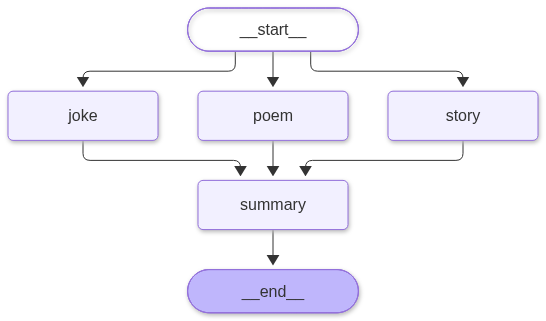

In [41]:
workflow.compile()

In [42]:
parallel=workflow.compile()

In [44]:
parallel.invoke({"topic": "AI"})

{'topic': 'AI',
 'story': '**Muse**\n\nThe first time Alex saw the poem, it was on a coffee‑stained napkin at a downtown café, the words scrawled in a hurried hand that seemed to be written by someone who had just stepped out of a dream.\n\n“*The city breathes, a quiet sigh,  \nIts neon pulse, a lullaby.*”\n\nIt was the sort of line that made Alex’s heart skip a beat. The café’s owner, an old woman named Mrs. Patel, had been humming a tune while she waited for her order. Alex had been working on a new project called Muse—a generative AI that could write poetry—when the napkin caught his eye. He was intrigued, not only by the poem itself but by the idea that the machine could produce something that felt alive.\n\nMuse was a neural network built on a lattice of transformer layers, trained on centuries of poetry—from the sonnets of Shakespeare to the haikus of Bashō. Its architecture was elegant, but Alex knew that no amount of data could guarantee that the output would ever feel… real. H

In [45]:
parallel.invoke({'topic':"Humans"})

{'topic': 'Humans',
 'story': '**The Last Light of Lumen**\n\nIn the city of Lumen the nights were never dark. A lattice of light‑nodes hung from every building, pulsing in rhythm with the collective heartbeat of the populace. Each citizen carried a neural‑link in the palm of their hand, a thin, iridescent ribbon that wove their thoughts into the city’s vast tapestry. Conversations were no longer spoken; they were felt. The city itself had become a living organism, its consciousness a mesh of billions of human minds.\n\nMaya had grown up in that glow. She knew the taste of the electric hum that ran through the veins of the city, the way her thoughts could be shared with anyone in seconds. She could have been a programmer, an engineer, a poet—anything the city’s algorithms suggested. But there was a part of her that felt the world was a little too clean, a little too efficient, and she had never quite fit into the smooth, data‑driven rhythm of Lumen.\n\nShe spent her evenings in the old

### Routing workflow

In [46]:
class RoutingState(TypedDict):
    user_query:str
    decision:str
    output:str

In [51]:
user_input="Write poem about Food"

In [52]:
llm.invoke(f"""Please classify user input {user_input} into story, joke and poem return only label""")

AIMessage(content='poem', additional_kwargs={'reasoning_content': 'The user wants classification. Input: "Write poem about Food". They want to classify into story, joke, poem. The input is a request: "Write poem about Food". That is a request to produce a poem. So the classification label should be "poem". They want only the label. So output: poem.'}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 88, 'total_tokens': 166, 'completion_time': 0.087314195, 'completion_tokens_details': {'reasoning_tokens': 67}, 'prompt_time': 0.036616711, 'prompt_tokens_details': None, 'queue_time': 0.371943287, 'total_time': 0.123930906}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ce54c53bd5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1f7c2-a5bb-77d2-a9aa-28dbc6fc9873-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 88, 'output_tokens': 78, 'total_tokens': 166, 

In [53]:
from pydantic import BaseModel,Field
from typing_extensions import Literal

In [62]:
class Decision(BaseModel):
    decision: Literal["poem","story","joke"] = Field(description="based on input take label decision story, poem and joke")

In [63]:
routing_llm=llm.with_structured_output(Decision)

In [71]:
user_input = "Write poem about Food"

In [72]:
response=routing_llm.invoke(f"""Please classify user input {user_input} into story, joke and poem return only label""")

In [73]:
response.decision

'poem'

In [74]:
def routing_agent(state:RoutingState):
    response=routing_llm.invoke(f"Please classify user input {state['user_query']} into story, poem, joke")
    return {"decision":response.decision}

def write_poem(state:RoutingState):
    response=llm.invoke(f"Write a poem on this topic {state['user_query']}")
    return {"output":response.content}

def write_joke(state:RoutingState):
    response=llm.invoke(f"Write a joke on this topic {state['user_query']}")
    return {"output":response.content}

def write_story(state:RoutingState):
    response=llm.invoke(f"Write a story on this topic {state['user_query']}")
    return {"output":response.content}

In [75]:
workflow=StateGraph(RoutingState)

In [76]:
workflow.add_node("routing_agent",routing_agent)
workflow.add_node("write_joke",write_joke)
workflow.add_node("write_poem",write_poem)
workflow.add_node("write_story",write_story)

In [ ]:
def route_decision(state:RoutingState):
    